# DL-01: Automated Waste Classification
### Neural Networks and Intelligent Applications — Deep Learning Pipeline
**Domain:** Sustainability & Municipal Recycling Automation  
**Author:** Roshan Alexander  
**Dataset:** Stanford TrashNet (Garbage Classification)  
**Architectures:** Custom CNN Baseline vs. Pretrained MobileNetV2 (Transfer Learning)

---
## Pipeline Architecture
1. **Environment Setup & Hardware Verification**
2. **Dataset Acquisition & Stratified Splitting (Zero Data Leakage)**
3. **Exploratory Data Analysis (EDA)**
4. **Data Augmentation & PyTorch DataLoader Architecture**
5. **Model Design: Custom CNN Baseline vs. MobileNetV2**
6. **Training Engine with Mixed Precision & Checkpointing**
7. **Rigorous Evaluation on Held-Out Test Split (15%)**
8. **Error Analysis & Confusion Patterns**
9. **Explainable AI (Grad-CAM Visual Attention Maps)**
10. **Circular Economy & Recycling Recommendation Engine**

## 1. Environment Setup & Hardware Verification

In [1]:
import os
import sys
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
import torch.nn as nn
from torchvision import transforms

# Add project root to sys.path
sys.path.insert(0, os.path.abspath('..'))

from src.dataset import CLASS_NAMES, CLASS_TO_IDX, find_dataset_dir, create_or_load_splits, get_transforms, get_dataloaders
from src.models import build_model, count_parameters
from src.predict import SUSTAINABILITY_GUIDE, WasteClassifierPredictor
from src.gradcam import GradCAM

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch Version: {torch.__version__}')
print(f'Active Device: {device}')
if torch.cuda.is_available():
    print(f'GPU Device Name: {torch.cuda.get_device_name(0)}')


PyTorch Version: 2.6.0+cu124
Active Device: cuda
GPU Device Name: NVIDIA GeForce RTX 3050 6GB Laptop GPU


## 2. Dataset Acquisition & Stratified Splitting
We enforce a strict 70% Train, 15% Validation, 15% Test partition with random seed 42 to guarantee zero data leakage.

In [2]:
splits_df = pd.read_csv('../data/splits.csv')
print(f'Total Dataset Size: {len(splits_df)} images')
print('\nPartition breakdown:')
print(splits_df['split'].value_counts())
print('\nClass breakdown per partition:')
print(pd.crosstab(splits_df['class_name'], splits_df['split']))


Total Dataset Size: 2527 images

Partition breakdown:
split
train    1768
test      380
val       379
Name: count, dtype: int64

Class breakdown per partition:
split       test  train  val
class_name                  
cardboard     60    282   61
glass         76    350   75
metal         62    287   61
paper         89    416   89
plastic       73    337   72
trash         20     96   21


## 3. Exploratory Data Analysis & Sample Waste Items

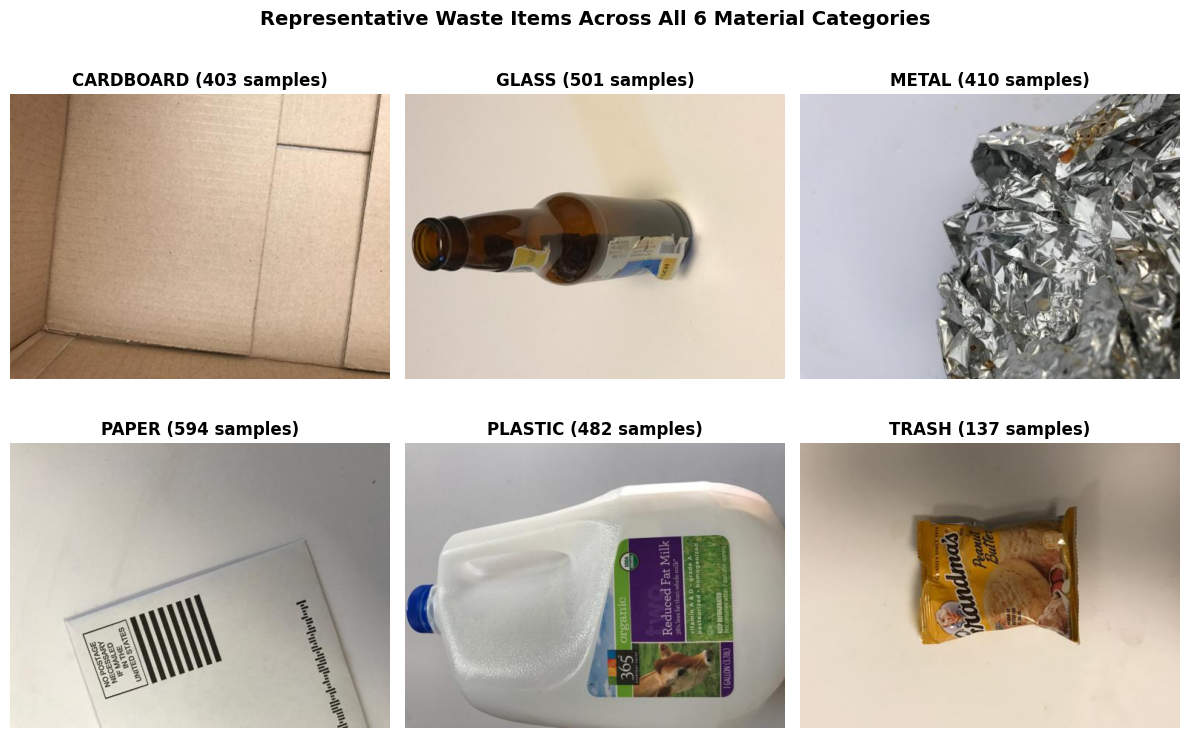

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for idx, cls in enumerate(CLASS_NAMES):
    sample_path = splits_df[splits_df['class_name'] == cls].iloc[0]['filepath']
    img = Image.open(sample_path).convert('RGB')
    axes[idx].imshow(img)
    axes[idx].set_title(f"{cls.upper()} ({splits_df[splits_df['class_name'] == cls].shape[0]} samples)", fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('Representative Waste Items Across All 6 Material Categories', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Deep Learning Architectures
Comparing our 4-stage Custom CNN baseline with MobileNetV2 transfer learning.

In [4]:
baseline_model = build_model('baseline')
mobilenet_model = build_model('mobilenetv2', pretrained=False)

b_params = count_parameters(baseline_model)
m_params = count_parameters(mobilenet_model)

print(f"Custom CNN Baseline Parameters: {b_params['total']:,} total")
print(f"MobileNetV2 Classifier Parameters: {m_params['total']:,} total")


Custom CNN Baseline Parameters: 652,838 total
MobileNetV2 Classifier Parameters: 2,553,350 total


## 5. Training and Validation Convergence
Inspecting loss decay and validation accuracy progression from experiments.

In [5]:
history_files = [
    ('../results/history_baseline.json', 'Baseline CNN'),
    ('../results/history_mobilenetv2.json', 'MobileNetV2')
]

for h_path, name in history_files:
    if os.path.exists(h_path):
        with open(h_path) as f:
            h = json.load(f)
        print(f"{name} -> Best Val Acc: {h['best_val_acc']*100:.2f}% at Epoch {h['best_epoch']}")


Baseline CNN -> Best Val Acc: 72.30% at Epoch 13
MobileNetV2 -> Best Val Acc: 92.61% at Epoch 13


## 6. Evaluation on Held-Out Test Split (15%)

In [6]:
metrics_files = [
    ('../results/metrics_baseline.json', 'Custom CNN Baseline'),
    ('../results/metrics_mobilenetv2.json', 'MobileNetV2 Transfer Learning')
]

for m_path, label in metrics_files:
    if os.path.exists(m_path):
        with open(m_path) as f:
            m = json.load(f)
        print(f'=== {label} ===')
        print(f"  Test Accuracy:    {m['accuracy']*100:.2f}%")
        print(f"  Macro Precision:  {m['macro_precision']*100:.2f}%")
        print(f"  Macro Recall:     {m['macro_recall']*100:.2f}%")
        print(f"  Macro F1-Score:   {m['macro_f1']*100:.2f}%")
        print(f"  Weighted F1:      {m['weighted_f1']*100:.2f}%\n")


=== Custom CNN Baseline ===
  Test Accuracy:    68.68%
  Macro Precision:  75.46%
  Macro Recall:     65.05%
  Macro F1-Score:   67.94%
  Weighted F1:      69.23%

=== MobileNetV2 Transfer Learning ===
  Test Accuracy:    93.68%
  Macro Precision:  93.67%
  Macro Recall:     93.70%
  Macro F1-Score:   93.54%
  Weighted F1:      93.69%



## 7. Explainable AI (Grad-CAM Activation Heatmaps)

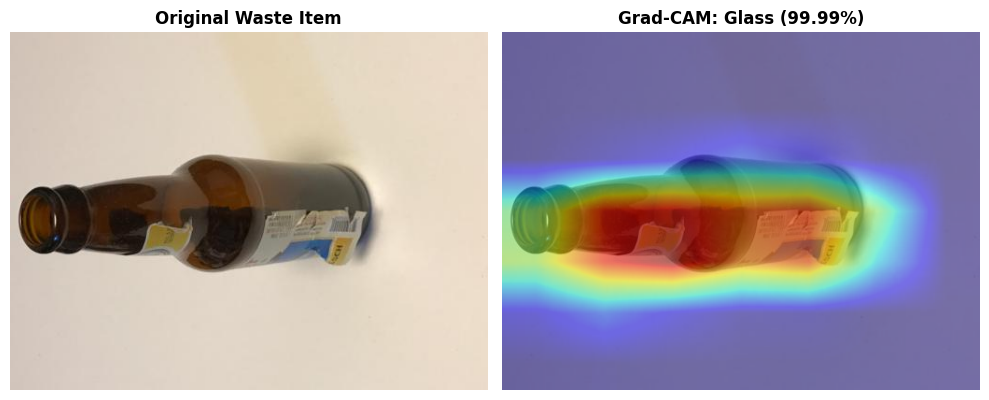

In [7]:
if os.path.exists('../models/best_mobilenetv2.pt'):
    predictor = WasteClassifierPredictor('../models/best_mobilenetv2.pt', model_name='mobilenetv2')
    sample_img_path = splits_df[splits_df['class_name'] == 'glass'].iloc[0]['filepath']
    
    res = predictor.predict(sample_img_path, compute_gradcam=True)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    ax1.imshow(res['original_image'])
    ax1.set_title('Original Waste Item', fontweight='bold')
    ax1.axis('off')
    
    ax2.imshow(res['gradcam_overlay'])
    ax2.set_title(f"Grad-CAM: {res['predicted_class'].capitalize()} ({res['confidence_percentage']})", fontweight='bold')
    ax2.axis('off')
    plt.tight_layout()
    plt.show()


## 8. Sustainability & Circular Economy Advisory Integration

In [8]:
for cls in CLASS_NAMES:
    info = SUSTAINABILITY_GUIDE[cls]
    print(f"{info['icon']} {cls.upper()}: {info['bin_label']}")
    print(f"   Recyclable: {info['recyclable']} | Decomposition: {info['decomposition_time']}")
    print(f"   CO2 Benefit: {info['co2_saved_kg_per_kg']} kg CO2e / kg\n")


📦 CARDBOARD: Blue Bin (Paper & Cardboard)
   Recyclable: True | Decomposition: 2 months (in aerated soil), but landfill burial locks carbon and creates methane.
   CO2 Benefit: 0.9 kg CO2e / kg

🍾 GLASS: Green Bin (Glass Recycling)
   Recyclable: True | Decomposition: 1,000,000+ years in natural environments (practically immortal).
   CO2 Benefit: 0.315 kg CO2e / kg

🥫 METAL: Yellow / Grey Bin (Dry Metals)
   Recyclable: True | Decomposition: 80 to 200 years for aluminum; 50 to 100 years for tin/steel cans.
   CO2 Benefit: 9.13 kg CO2e / kg

📄 PAPER: Blue Bin (Paper Stream)
   Recyclable: True | Decomposition: 2 to 6 weeks under aerated composting conditions.
   CO2 Benefit: 1.32 kg CO2e / kg

🧴 PLASTIC: Yellow Bin (Plastics & Packaging)
   Recyclable: True | Decomposition: 450 to 1,000 years, breaking down into persistent, toxic microplastics.
   CO2 Benefit: 1.5 kg CO2e / kg

🗑️ TRASH: Black / Dark Grey Bin (General Landfill)
   Recyclable: False | Decomposition: Centuries for synthe